# Systematics uncertainties estimates from Jackniffe tests (data perturbations)

## Random FoV masking:

How sensitive is the fit to the removal of a randomly selected subset of the field of view?

**Goal:** Probes the stability of the fit with respect to spatially localized systematic effects, such as diffuse-model mismatches, acceptance uncertainties, or residual background structures.


## Imports

In [1]:
from gammapy.datasets import Datasets
from gammapy.modeling import Fit
from gammapy.modeling.models import FoVBackgroundModel, PowerLawNormSpectralModel, TemplateSpatialModel, SkyModel, Models
from gammapy.catalog import CATALOG_REGISTRY
from gammapy.maps import Map
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from gammapy.datasets.utils import set_and_restore_mask_fit
from scipy.stats import gaussian_kde
import copy
from gammapy.datasets import Datasets
import gc
import corner

/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Load datasets

From previous notebook 2a_hess_data_reduction.ipynb


In [2]:
datasets = Datasets.read(
    filename="./datasets/hess_rxj_datasets.yaml",
    filename_models="./models/hess_rxj_models.yaml",
)


In [3]:
model_iem = datasets.models["IEM_varmin_rescaled"]

In [4]:
bkgs = [FoVBackgroundModel(dataset_name=d.name,
                                  spectral_model=PowerLawNormSpectralModel()
                                 ) for d in datasets]

In [5]:
geom = datasets[0].counts.geom

In [6]:
catalog_hgps = CATALOG_REGISTRY.get_cls("hgps")()  # load HGPS catalog
in_geom = geom.to_image().contains(catalog_hgps.positions)
catalog_hgps_geom = catalog_hgps[in_geom]
models_hgps_geom = catalog_hgps_geom.to_models()


In [7]:
models_hgps_geom.freeze()
for m in models_hgps_geom:
    m.spatial_model.lon_0.min = geom.footprint.galactic.l.value.min()
    m.spatial_model.lon_0.max = geom.footprint.galactic.l.value.max()
    m.spatial_model.lat_0.min = geom.footprint.galactic.b.value.min()
    m.spatial_model.lat_0.max = geom.footprint.galactic.b.value.max()
    if m.spatial_model.tag[0] == "ShellSpatialModel":
        model_name = m.name
        m.unfreeze("spectral")
        m.spectral_model.amplitude.min = 0
        m.spectral_model.amplitude.max = m.spectral_model.amplitude.value*10
        m.spectral_model.index.min = 1
        m.spectral_model.index.max = 3
        m.spectral_model.lambda_.min = 1/10
        m.spectral_model.lambda_.max = 1/2
        model_ref = m

models = models_hgps_geom + bkgs + [model_iem]

In [8]:
#just speed-up this tutorial
datasets = Datasets([d.downsample(factor=5).cutout(d.counts.geom.center_skydir, width=5*u.deg) for d in datasets])

HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found


In [9]:
datasets.models = models.copy()

In [10]:
len(datasets)

12

## Stacked

In [11]:
fit = Fit()

In [12]:
stacked = datasets.copy().stack_reduce(name="stacked")



(<WCSAxes: >,
 <Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals (data - model)'>)

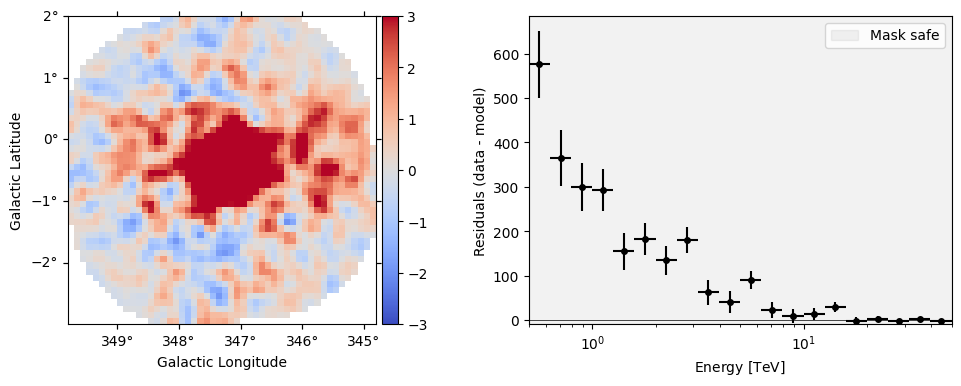

In [13]:
stacked.plot_residuals(kwargs_spatial=dict(vmin=-3, vmax=3))

In [14]:
bkg_stacked =  FoVBackgroundModel(dataset_name=stacked.name,
                                  spectral_model=PowerLawNormSpectralModel()
                                 )
#bkg_stacked.spectral_model.tilt.frozen=False
models_stacked = models.copy() + [bkg_stacked] 
stacked.models =  models_stacked

In [15]:
%%time
results_stacked = fit.run(stacked)
results_stacked

Value 0.07751937955617905 is outside bounds [0.1, 0.5] for parameter 'lambda_'
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


CPU times: user 2.76 s, sys: 105 ms, total: 2.86 s
Wall time: 2.89 s


(<WCSAxes: >,
 <Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals (data - model)'>)

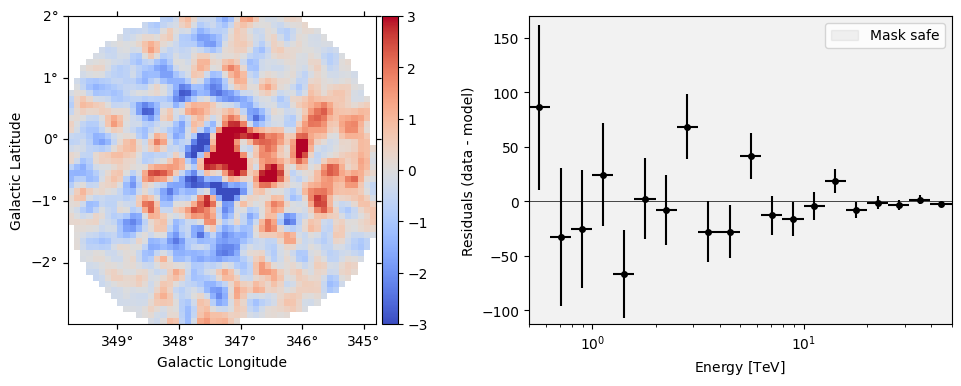

In [16]:
stacked.plot_residuals(kwargs_spatial=dict(vmin=-3, vmax=3))

## Random masking pixels subset

Here instead of masking obervations we are going to mask groups of pixels in the datasets.



### Test background spatial variations

In [17]:
def mask_random_patches(geom, mask_fraction=0.3, patch_fraction=0.03, seed=None):
    """
    Apply random patches to mask a fraction of a Gammapy Map.

    Parameters
    ----------
    map_obj : gammapy.maps.Map
        The input 3D Gammapy map.
    mask_fraction : float
        Fraction of the map to mask (e.g., 0.30 for 30%).
    patch_fraction : float
        Fraction of the map covered by each patch (e.g., 0.05 for 5%).
    seed : int or None
        Random seed for reproducibility.

    Returns
    -------
    masked_map : gammapy.maps.Map
        A copy of the map with masked regions set to NaN.
    mask : np.ndarray
        Boolean mask array (True = keep, False = masked).
    """
    if seed is not None:
        np.random.seed(seed)

    shape = geom.to_image().data_shape
    total_pixels = np.prod(shape)

    patch_size = int(total_pixels * patch_fraction)
    num_patches = int(mask_fraction / patch_fraction)

    mask = np.ones(shape, dtype=bool)

    for _ in range(num_patches):
        # Random center in spatial dimensions
        lat_idx = np.random.randint(0, shape[0])
        lon_idx = np.random.randint(0, shape[1])

        # Approx square patch
        patch_side = int(np.sqrt(patch_size))
        lat_start = max(0, lat_idx - patch_side // 2)
        lon_start = max(0, lon_idx - patch_side // 2)

        lat_end = min(shape[0], lat_start + patch_side)
        lon_end = min(shape[1], lon_start + patch_side)

        mask[lat_start:lat_end, lon_start:lon_end] = False

    return Map.from_geom(geom, data=mask)


In [18]:
mask_fit = mask_random_patches(geom)
mask_fit.plot_interactive()

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

In [19]:
fit = Fit()

In [20]:
%%time
results_samples = []
n_samples = 3000
for k in range(n_samples):
    print(k+1, f"/{n_samples}")
    
    datasets_stacked = Datasets(stacked)
    datasets_stacked.models = models_stacked.copy()
    
    mask_fit = mask_random_patches(geom, mask_fraction=0.3)

    with set_and_restore_mask_fit(datasets_stacked, mask_fit) as masked_datasets:
        results_k = fit.run(masked_datasets)
        results_samples.append(results_k.models)

    del mask_fit #force to free memory to avoid leak
    gc.collect()


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


1 /3000


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


2 /3000


Model HESS J1713-397 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


...

2998 /3000


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


2999 /3000


Model HESS J1718-385 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


3000 /3000
CPU times: user 2h 27min 1s, sys: 1min 35s, total: 2h 28min 37s
Wall time: 2h 30min 1s


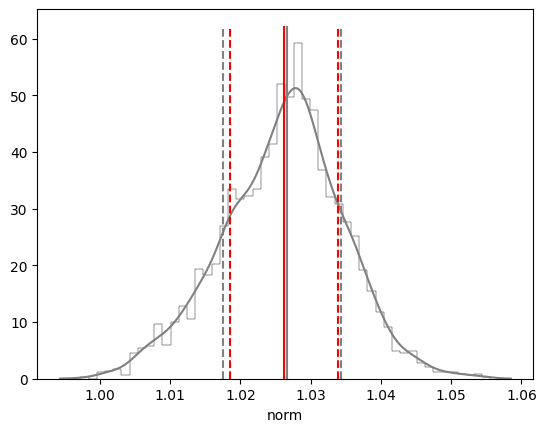

In [21]:
# let's check if subset of the map drives/bias the fit of the background model
bkg_name = stacked.background_model.name
for par_name in stacked.background_model.parameters.free_parameters.names:
    par_samples = []
    for k in range(n_samples):
        par_samples.append(results_samples[k][bkg_name].parameters[par_name].value)
    plt.figure()
    plt.hist(par_samples, bins=50, color="k", lw=0.3, histtype="step", density=True)
    xl=plt.xlim()
    yl = plt.ylim()
    x = np.linspace(xl[0], xl[1], 1000)
    plt.plot(x, gaussian_kde(par_samples).pdf(x), color="gray")
    plt.plot([np.percentile(par_samples, 50)]*2, yl , color="gray", ls="-", label="systematic (jackknife)")
    plt.plot([np.percentile(par_samples, 16)]*2, yl , color="gray", ls="--")
    plt.plot([np.percentile(par_samples, 84)]*2, yl , color="gray", ls="--")
    value = results_stacked.models[bkg_name].parameters[par_name].value
    error = results_stacked.models[bkg_name].parameters[par_name].error
    plt.plot([value]*2, yl , color="r", label="statistic")
    plt.plot([value-error]*2, yl , color="r", ls="--")
    plt.plot([value+error]*2, yl , color="r", ls="--")
    plt.xlabel(par_name)

The background normalisation distribution from the jackknife seems almost symmetric, with no strong apparent bias. The variance will depend on the size of the patch considered and on the level of systematic error in the morphology of the background template.

### Test variations across the shell

In the observation jackknife, we found that the amplitude distribution exhibited an unusual pattern. This could be because the observations are position-dependent, and masking different observations alters the sensitivity across the shell. As a result, different substructures may drive the fit. To investigate this, we could perform an additional test by applying the mask to random pixel positions within the shell.

In [22]:
import numpy as np

from gammapy.maps import Map


def make_random_box_mask(
    geom,
    position,
    radius,
    box_size=11,
    seed=None,
):
    """Create a mask with a randomly masked box.

    Parameters
    ----------
    geom : `~gammapy.maps.Geom`
        Geometry of the mask.
    position : `~astropy.coordinates.SkyCoord`
        Center position.
    radius : `~astropy.units.Quantity`
        Radius within which the box center is selected.
    box_size : int, optional
        Size of the box in pixels. Must be odd.
    random_state : int or `~numpy.random.Generator`, optional
        Random state.

    Returns
    -------
    mask : `~gammapy.maps.Map`
        Boolean mask.
    """
    rng = np.random.default_rng(seed)

    coords = geom.to_image().get_coord()
    separation = coords.skycoord.separation(position)

    iy, ix = np.where(separation < radius)

    if len(ix) == 0:
        raise ValueError("No pixels found within the given radius.")

    idx = rng.integers(len(ix))

    y0 = iy[idx]
    x0 = ix[idx]

    half_size = box_size // 2

    y_min = max(0, y0 - half_size)
    y_max = min(geom.data_shape[-2], y0 + half_size + 1)

    x_min = max(0, x0 - half_size)
    x_max = min(geom.data_shape[-1], x0 + half_size + 1)

    mask = Map.from_geom(geom, data=True, dtype=bool)
    mask.data[..., y_min:y_max, x_min:x_max] = False

    return mask

In [23]:
shell_model =  models_stacked[model_name]
radius =  shell_model.spatial_model.radius.quantity + shell_model.spatial_model.width.quantity
mask = make_random_box_mask(geom, shell_model.position, radius)
mask.plot_interactive()

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

In [24]:
%%time
results_samples = []
n_samples = 3000
for k in range(n_samples):
    print(k+1, f"/{n_samples}")
    
    datasets_stacked = Datasets(stacked)
    datasets_stacked.models = models_stacked.copy()
    
    mask_fit = make_random_box_mask(geom, shell_model.position, radius, box_size=11)

    with set_and_restore_mask_fit(datasets_stacked, mask_fit) as masked_datasets:
        results_k = fit.run(masked_datasets)
        results_samples.append(results_k.models)

    del mask_fit #force to free memory to avoid leak
    gc.collect()

Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


1 /3000


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


2 /3000


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


...

2998 /3000


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


2999 /3000


Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (Galactic): (l, b) in deg
    (344.23278809, -0.18636711)> is outside valid IRF map range, using nearest IRF defined within


3000 /3000
CPU times: user 2h 21min 44s, sys: 1min 39s, total: 2h 23min 23s
Wall time: 2h 24min 37s


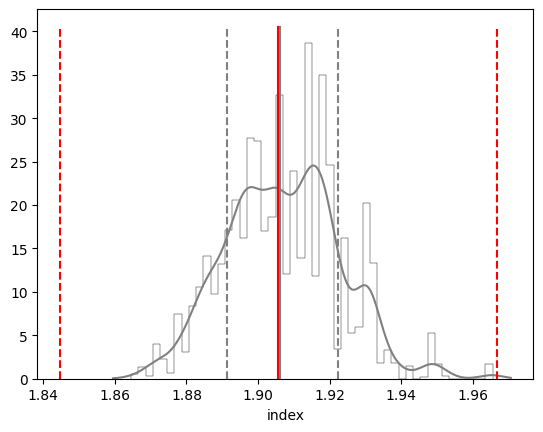

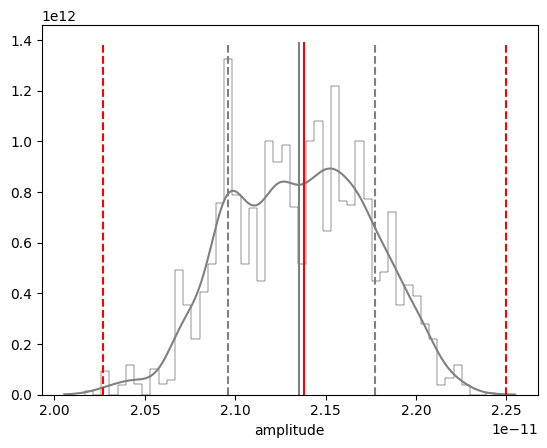

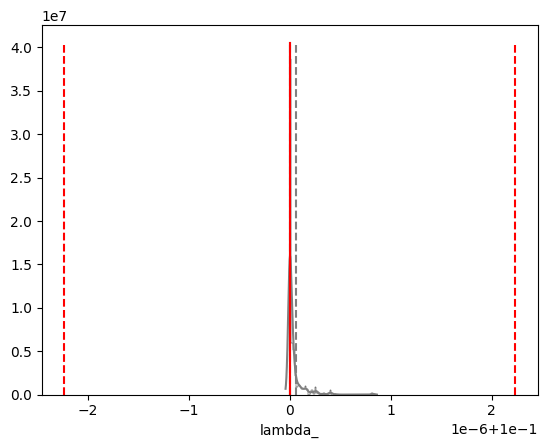

In [25]:
# let's check if subset of the map drives/bias the fit of the shell
for par_name in shell_model.parameters.free_parameters.names:
    par_samples = []
    for k in range(n_samples):
        par_samples.append(results_samples[k][model_name].parameters[par_name].value)
    plt.figure()
    plt.hist(par_samples, bins=50, color="k", lw=0.3, histtype="step", density=True)
    xl=plt.xlim()
    yl = plt.ylim()
    x = np.linspace(xl[0], xl[1], 1000)
    plt.plot(x, gaussian_kde(par_samples).pdf(x), color="gray")
    plt.plot([np.percentile(par_samples, 50)]*2, yl , color="gray", ls="-", label="systematic (jackknife)")
    plt.plot([np.percentile(par_samples, 16)]*2, yl , color="gray", ls="--")
    plt.plot([np.percentile(par_samples, 84)]*2, yl , color="gray", ls="--")
    value = results_stacked.models[model_name].parameters[par_name].value
    error = results_stacked.models[model_name].parameters[par_name].error
    plt.plot([value]*2, yl , color="r", label="statistic")
    plt.plot([value-error]*2, yl , color="r", ls="--")
    plt.plot([value+error]*2, yl , color="r", ls="--")
    plt.xlabel(par_name)